# NFL Game Simulator v5: games + player props

**Files that go together in one folder:** `nfl_game_sim_v5.py` (game engine), `nfl_props_v5.py` (player props), `fetch_dk_props.py` (DraftKings lines downloader), this notebook. If you replace a `.py` file, restart the kernel (Kernel → Restart).

**What's new in v5: player props.** Projections for passing yards, attempts, completions, passing TDs, rushing yards and attempts, receiving yards, receptions, and anytime TD. They're built from:
1. **Team volume:** pass attempts, targets, and carries per game, adjusted for game script (teams expected to lead run more).
2. **Each player's role:** target, carry, and attempt share over his recent games. Shares are rescaled so a team's players never add up to more than 100%, and teammates who are out free up their share.
3. **Efficiency:** yards per target, carry, and attempt, catch rate, and completion %, shrunk toward position averages and adjusted for the opponent's defense.
4. **Touchdowns:** the game simulation's projected points, turned into team TDs and then each player's share.

The props layer only reads the game simulation's output (projected points, starting QB). It never changes game predictions, and the notebook checks this in section 5.

Game settings, referee names, and data files are documented in the settings guide doc.

In [1]:
# First time only
# %pip install pandas numpy pyarrow matplotlib

In [2]:
import warnings; warnings.filterwarnings("ignore")
import os, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from nfl_game_sim_v5 import *
import nfl_props_v5 as props

CACHE = "nfl_data/prep_cache_v5.pkl"   # delete this file when you refresh the weekly data
if os.path.exists(CACHE):
    games, prep, injuries, stats = pickle.load(open(CACHE, "rb"))
else:
    games, pbp, injuries = load_all([2023, 2024, 2025, 2026])
    prep = prepare(games, pbp)
    del pbp
    add_qb_history(prep, range(2019, 2025))
    add_referee_history(prep, range(2019, 2023))
    rosters_all = pd.concat([load_rosters(y)[0] for y in (2023, 2024, 2025, 2026)])
    add_line_data(prep, [2023, 2024, 2025, 2026], rosters_all, injuries)
    stats = props.load_player_stats([2023, 2024, 2025, 2026], games)
    pickle.dump((games, prep, injuries, stats), open(CACHE, "wb"))
print("Data ready.")

Data ready.


## 1. Rosters, injuries, ratings

In [3]:
SEASON, WEEK, AS_OF = 2026, 4, "2026-09-29"
CARRY_FORWARD = True   # True until this week's Friday injury report is out, then False

rosters, depth = load_rosters(SEASON)
ctx = build_context(SEASON, WEEK, rosters, injuries, depth, carry_forward=CARRY_FORWARD)
model = fit_model(prep, AS_OF)
P = props.fit_props(model, stats)   # props inputs (read-only on the game model)
print("Model and props ready.")

Model and props ready.


## 2. Simulate one game 50000X

CLE (D.Watson) @ PIT (A.Rodgers)
  Win prob:    PIT 53.5% | CLE 45.6% | tie 0.9%
  Final proj:  PIT 22.2 - CLE 20.9   (halftime 11.2 - 9.7)
  Line:        PIT -1.3   Total 43.2
  Possessions: PIT 10.9, CLE 10.9   Turnovers: PIT 1.00, CLE 1.16
  Most likely finals: PIT 20 - CLE 17 (0.9%), PIT 27 - CLE 20 (0.8%), PIT 20 - CLE 13 (0.8%)
  Conditions:  82F, wind 5 mph (your input) (total -0.1) | rest: PIT 7 days, CLE 7 days (PIT -0.1)
  Referee:     Shawn Hochuli: 12.5 flags/game (league 12.0), away-minus-home +0.46 (118 games) (PIT +0.00)
  PIT offense: C.Boswell (76/86, +0.20 vs avg) | QB pressured 15.2% of dropbacks (league 15.5%) | red-zone TD 55.6% (league 58.3%)
  CLE offense: A.Szmyt (30/33, +0.08 vs avg) | QB pressured 17.5% of dropbacks (league 15.5%) | red-zone TD 56.1% (league 58.3%)
  CLE defensive starters out: Tyson Campbell (CB, reserve/inactive)


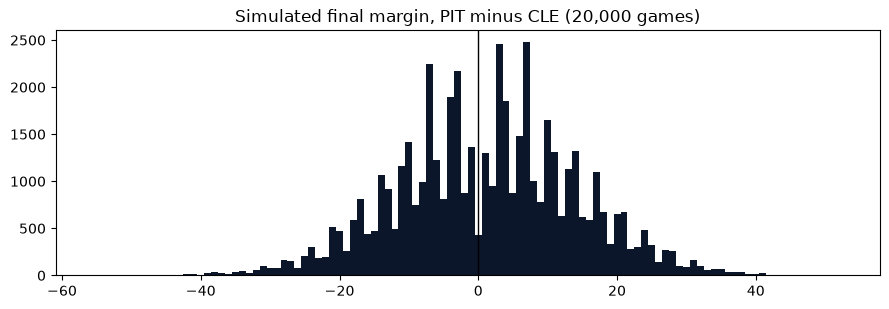

In [39]:
HOME, AWAY, NEUTRAL = "PIT", "CLE", False
HOME_QB, AWAY_QB, OUT = None, None, None
WEATHER = {"temp" : 82, "wind" : 5}  # e.g. {"temp": 38, "wind": 18}

game = simulate_game(model, HOME, AWAY, n_sims=50000, neutral=NEUTRAL, seed=42, home_qb=HOME_QB,
                     away_qb=AWAY_QB, out_players=OUT, ctx=ctx, weather=WEATHER, referee=REFEREE)
print_game(game)

margin = game["home_scores"] - game["away_scores"]
plt.figure(figsize=(9, 3.2))
plt.hist(margin, bins=np.arange(margin.min() - .5, margin.max() + 1.5), color="#0B162A")
plt.axvline(0, color="black", lw=1)
plt.title(f"Simulated final margin, {HOME} minus {AWAY} (20,000 games)")
plt.tight_layout(); plt.show()

In [5]:
factor_breakdown(model, HOME, AWAY, ctx=ctx, home_qb=HOME_QB, away_qb=AWAY_QB, out_players=OUT, weather=WEATHER, referee=REFEREE)

,factor added,CHI margin,change,CHI win %
0,Team points ratings only,3.4,0.0,59.3
1,EPA efficiency (pass/run),2.4,-1.0,57.8
2,Starting QB,-1.4,-3.8,45.8
3,Skill players out,-1.6,-0.1,45.2
4,Game plan vs similar D,-1.4,0.1,44.2
5,Style matchup residual,-0.2,1.2,49.3
6,Turnover tendencies / QB mistakes,-0.5,-0.3,47.6
7,4th-down aggressiveness,-0.5,-0.0,47.4
8,Halftime adjustments,-0.7,-0.2,48.1
9,Head-to-head (2 yrs),-0.1,0.6,49.8


## 3. Player props for this game
Uses the game simulation above, so any QB, OUT, weather, or referee settings flow through. `anytime_td` is a probability.

In [26]:
game_props = props.project_game(model, P, HOME, AWAY, ctx=ctx, sim=game, out_players=OUT)

In [27]:
def to_american(p):
    """Win probability -> fair American odds (no sportsbook margin)."""
    p = min(max(float(p), 0.001), 0.999)
    return f"-{round(100 * p / (1 - p))}" if p >= 0.5 else f"+{round(100 * (1 - p) / p)}"

In [31]:
# Quarterbacks
OUT="Caleb Williams"
qb_cols = ["player", "team", "pass_att", "completions", "pass_yds", "pass_tds",
           "rush_att", "rush_yds", "anytime_td"]
qbs = game_props[game_props.pos == "QB"][qb_cols].copy()
qbs["Model_td_odds"] = qbs.anytime_td.apply(to_american)   # QB cell
qbs["anytime_td"] = (qbs.anytime_td * 100).round(0).astype(int).astype(str) + "%"
qbs.round(1).sort_values("team")


,player,team,pass_att,completions,pass_yds,pass_tds,rush_att,rush_yds,anytime_td,Model_td_odds
8,C.Keenum,CHI,33.8,20.4,221.4,1.4,1.4,6.2,4%,+2258
11,Jalen Hurts,PHI,31.4,19.0,215.8,1.5,3.6,16.9,9%,+987


In [32]:
# Running backs
rb_cols = ["player", "team", "rush_att", "rush_yds", "targets", "receptions", "rec_yds", "anytime_td"]
rbs = game_props[game_props.pos.isin(["RB", "FB"])][rb_cols].copy()
rbs["Model_td_odds"] = rbs.anytime_td.apply(to_american)   # RB cell
rbs["anytime_td"] = (rbs.anytime_td * 100).round(0).astype(int).astype(str) + "%"
rbs.round(1).sort_values(["team", "rush_yds"], ascending=[True, False])

,player,team,rush_att,rush_yds,targets,receptions,rec_yds,anytime_td,Model_td_odds
1,D'Andre Swift,CHI,17.4,73.8,2.1,1.6,13.6,45%,+122
5,Kyle Monangai,CHI,11.0,48.3,2.4,1.9,14.7,34%,+192
10,Saquon Barkley,PHI,10.5,48.8,2.4,1.7,13.0,32%,+215
15,Jaydon Blue,PHI,6.4,26.6,0.2,0.1,1.1,17%,+504
14,Tank Bigsby,PHI,5.2,21.7,0.7,0.6,4.5,16%,+525


In [33]:
# Wide receivers and tight ends
wr_cols = ["player", "pos", "team", "targets", "receptions", "rec_yds", "anytime_td"]
wrs = game_props[game_props.pos.isin(["WR", "TE"])][wr_cols].copy()
wrs["Model_td_odds"] = wrs.anytime_td.apply(to_american)
wrs["anytime_td"] = (wrs.anytime_td * 100).round(0).astype(int).astype(str) + "%"
wrs.round(1).sort_values(["team", "rec_yds"], ascending=[True, False])

,player,pos,team,targets,receptions,rec_yds,anytime_td,Model_td_odds
6,Luther Burden III,WR,CHI,6.0,3.6,47.9,19%,+418
4,Colston Loveland,TE,CHI,6.6,4.0,45.6,21%,+365
3,Rome Odunze,WR,CHI,5.0,2.7,40.4,15%,+562
0,Kalif Raymond,WR,CHI,4.1,2.7,35.1,14%,+596
7,Sam Roush,TE,CHI,3.0,1.9,20.0,12%,+738
2,Cole Kmet,TE,CHI,2.3,1.5,15.9,14%,+625
12,DeVonta Smith,WR,PHI,7.9,4.9,67.6,30%,+230
9,Zach Ertz,TE,PHI,6.4,4.4,49.0,21%,+366
13,Dontayvion Wicks,WR,PHI,3.8,2.4,36.9,21%,+366
16,Makai Lemon,WR,PHI,2.2,1.4,17.7,11%,+833


### Probability of going over a line
Change the market, projection, and line to check any prop.

In [10]:
PLAYER, MARKET, LINE = None, "rec_yds", 89.5   # PLAYER None = top projected player in that market
row = (game_props[game_props.player == PLAYER] if PLAYER else game_props.sort_values(MARKET, ascending=False)).iloc[0]
p_over = float(props.prob_over(row[MARKET], LINE, MARKET))
print(f"{row.player}: projection {row[MARKET]:.1f} vs line {LINE} -> P(over) {p_over:.1%}, P(under) {1 - p_over:.1%}")

DeVonta Smith: projection 67.6 vs line 89.5 -> P(over) 28.9%, P(under) 71.1%


## 4. This week vs DraftKings
Run the downloader on your computer first (free Odds API plan covers the current week):
```
python fetch_dk_props.py current
```
It writes `dk_props_current.csv` next to this notebook. The table is sorted by the model's expected value per $1 at DraftKings' price. Treat positive EV as "worth a look," not a bet: section 6 shows how well the model has done against actual results.

In [11]:
week_props = props.project_week(model, P, SEASON, WEEK, ctx=ctx)
dk_ou_all, dk_yes_all = props.auto_dk_lines(max_age_hours=6)   # every game this week, ~100 credits

if dk_ou_all is not None:
    display(props.compare_to_dk(week_props, dk_ou_all, dk_yes_all).head(40))
else:
    week_cols = ["player", "pos", "team", "opp", "pass_yds", "rush_yds", "rec_yds",
                 "receptions", "anytime_td"]
    display(week_props[week_cols].round(1).sort_values(["team", "pos"]).head(40))

Couldn't pull DraftKings lines: No Odds API key found. Put it in odds_api_key.txt next to the notebook (just the key, nothing else) or set ODDS_API_KEY.


,player,pos,team,opp,pass_yds,rush_yds,rec_yds,receptions,anytime_td
114,Jacoby Brissett,QB,ARI,NYG,226.3,10.7,0.0,0.0,0.0
116,Bam Knight,RB,ARI,NYG,NaN,23.4,11.7,1.6,0.2
117,Tyler Allgeier,RB,ARI,NYG,NaN,21.0,10.4,1.6,0.2
122,Jeremiyah Love,RB,ARI,NYG,NaN,44.4,18.3,2.8,0.3
118,Trey McBride,TE,ARI,NYG,NaN,0.0,66.8,7.3,0.4
120,Elijah Higgins,TE,ARI,NYG,NaN,0.0,16.2,1.7,0.1
115,Kendrick Bourne,WR,ARI,NYG,NaN,0.0,25.2,2.1,0.1
119,Michael Wilson,WR,ARI,NYG,NaN,0.0,69.1,5.6,0.4
121,Marvin Harrison Jr.,WR,ARI,NYG,NaN,0.0,28.1,2.1,0.1
242,M.Penix,QB,ATL,NO,188.8,5.1,0.0,0.0,0.0


## 5. Check: props don't change game predictions

In [12]:
before = simulate_game(model, HOME, AWAY, 8000, seed=11, ctx=ctx)
_ = props.project_week(model, P, SEASON, WEEK, ctx=ctx, n_sims=2000)
after = simulate_game(model, HOME, AWAY, 8000, seed=11, ctx=ctx)
same = (before["home_win_pct"], before["proj_spread"]) == (after["home_win_pct"], after["proj_spread"])
print("Game prediction unchanged after running props:", same)

Game prediction unchanged after running props: True


## 6. Props backtest (~2 minutes)
Every week: refit using only earlier games, project props with that week's roster and injury report, then grade against what players actually did. Players who didn't play are dropped, the same way a sportsbook voids their props.

The comparison is a simple baseline: each player's average over his last 8 games. That's roughly what a casual bettor or a basic projection site uses. "Avg miss" is the average distance from the actual stat (for anytime TD it's the Brier score; lower is better).

In [13]:
prop_runs = [(2025, range(4, 19)), (2026, range(1, 4))]
prop_bt, prop_grades = {}, {}
for yr, wks in prop_runs:
    bt_p = props.backtest_props(games, prep, injuries, load_rosters(yr)[0], stats, yr, list(wks))
    prop_bt[yr] = bt_p
    prop_grades[yr] = props.grade_props(bt_p)
    print(f"{yr}:"); display(prop_grades[yr].round(3))

2025:


,players_graded,model_avg_miss,naive_avg_miss,model_bias,model_corr,naive_corr
pass_yds,434.0,60.777,65.879,-0.862,0.218,0.262
pass_att,434.0,6.917,8.029,0.743,0.226,0.176
completions,434.0,4.782,5.571,0.353,0.236,0.198
pass_tds,434.0,0.957,1.004,0.091,0.191,0.173
rush_yds,938.0,23.662,24.421,0.130,0.537,0.481
rush_att,938.0,3.732,3.961,0.103,0.660,0.609
rec_yds,2419.0,21.367,22.004,0.105,0.512,0.497
receptions,2419.0,1.562,1.607,0.022,0.517,0.509
anytime_td,3172.0,0.175,0.194,-0.019,0.258,0.199


2026:


,players_graded,model_avg_miss,naive_avg_miss,model_bias,model_corr,naive_corr
pass_yds,89.0,55.999,60.952,-8.452,0.277,0.239
pass_att,89.0,6.311,7.176,-0.303,0.366,0.247
completions,89.0,4.544,4.795,-0.740,0.413,0.310
pass_tds,89.0,0.913,0.937,-0.056,0.370,0.216
rush_yds,202.0,22.715,24.412,3.187,0.604,0.567
rush_att,202.0,3.996,4.309,0.549,0.695,0.643
rec_yds,507.0,22.151,22.918,-0.906,0.501,0.455
receptions,507.0,1.686,1.700,-0.096,0.448,0.445
anytime_td,668.0,0.173,0.191,-0.008,0.233,0.187


### Backtest vs DraftKings historical lines
Needs a paid Odds API plan (historical data starts May 2023). The 2025 season, Weeks 4-18, is about 13,500 credits, which fits the 20K plan:
```
python fetch_dk_props.py history 2025 --weeks 4-18 --dry-run   # check cost
python fetch_dk_props.py history 2025 --weeks 4-18
```
Break-even at standard -110 odds is 52.4%. `roi_5pct_edge_picks` = return per $1 on props where the model saw at least 5% expected value.

In [14]:
for yr in prop_bt:
    path = f"dk_props_{yr}.csv"
    if os.path.exists(path):
        dk_ou, dk_yes = props.load_dk_lines(path)
        print(f"{yr} vs DraftKings:"); display(props.grade_vs_dk(prop_bt[yr], dk_ou, dk_yes).round(3))
    else:
        print(f"No {path} yet.")

No dk_props_2025.csv yet.
No dk_props_2026.csv yet.


## 7. Game backtest vs Vegas (optional, ~3 minutes)
Set `RUN_GAME_BACKTEST = True` to re-run. Results only change when the data or model changes.

In [15]:
RUN_GAME_BACKTEST = False
if RUN_GAME_BACKTEST:
    results = {}
    for yr, wks in [(2026, [1, 2]), (2025, None), (2024, None)]:
        bt, _ = backtest(games, prep, injuries, load_rosters(yr)[0], yr, n_sims=4000, weeks=wks)
        results[f"{yr}"] = grade_vs_vegas(bt)
    display(pd.DataFrame(results))

## 8. Reference tables

In [16]:
coach_table(model)

,coach,4th_GOE_punt_zone,4th_GOE_fg_zone,halftime_off_swing,halftime_def_swing
team,,,,,
DAL,Brian Schottenheimer,0.128,0.041,-0.031,0.023
IND,Shane Steichen,0.093,0.015,-0.015,-0.026
CAR,Dave Canales,0.070,-0.006,0.028,0.027
BUF,Sean McDermott,0.064,0.153,0.020,0.049
DET,Dan Campbell,0.059,0.168,0.010,-0.037
ATL,Raheem Morris,0.042,0.008,-0.010,-0.021
KC,Andy Reid,0.042,-0.075,0.005,0.004
NYG,John Harbaugh,0.041,0.005,0.052,-0.038
PHI,Nick Sirianni,0.039,0.068,-0.053,-0.017


In [17]:
_, pbp26, _ = load_all([2026])

d = pbp26[(pbp26["week"].between(1, 2)) & (pbp26["qb_dropback"] == 1)]

w12 = (
    d.assign(to=d["interception"].fillna(0) + d["fumble_lost"].fillna(0))
     .groupby("id")
     .agg(name=("name", "first"),
          team=("posteam", "last"),
          db=("epa", "size"),
          epa_db=("epa", "mean"),
          to_db=("to", "mean"))
)

out = w12[w12["db"] >= 40].copy()
out["to_pct"] = (out["to_db"] * 100).round(3)

out.sort_values(["epa_db", "to_pct"], ascending=[False, True]).head(32)

,name,team,db,epa_db,to_db,to_pct
id,,,,,,
00-0037834,B.Purdy,SF,61,0.556138,0.016393,1.639
00-0034857,J.Allen,BUF,71,0.531373,0.000000,0.000
00-0035704,D.Lock,SEA,51,0.475840,0.000000,0.000
00-0033077,D.Prescott,DAL,72,0.388269,0.013889,1.389
00-0039918,C.Williams,CHI,70,0.314496,0.028571,2.857
00-0039150,B.Young,CAR,80,0.303267,0.025000,2.500
00-0036971,T.Lawrence,JAX,55,0.271026,0.018182,1.818
00-0034796,L.Jackson,BAL,66,0.258066,0.030303,3.030
00-0033106,J.Goff,DET,85,0.220010,0.011765,1.176


In [18]:
qb_table(model).head(32)

,name,team,db,epa_per_db,turnover_pct
qb_id,,,,,
00-0033873,P.Mahomes,KC,5447,0.222,1.879
00-0037834,B.Purdy,SF,1861,0.220,2.501
00-0034857,J.Allen,BUF,5000,0.183,2.278
00-0034796,L.Jackson,BAL,3580,0.170,2.214
00-0033077,D.Prescott,DAL,3904,0.146,2.231
00-0036442,J.Burrow,CIN,3535,0.120,2.141
00-0026498,M.Stafford,LA,4123,0.119,2.330
00-0039910,J.Daniels,WAS,1039,0.115,1.827
00-0033106,J.Goff,DET,4599,0.114,2.221


In [19]:
active_referees(model)

,games,flags_pg,away_minus_home_flags
referee,,,
Adrian Hill,117,12.69,0.62
Alan Eck,53,11.24,0.23
Alex Kemp,120,12.56,0.59
Alex Moore,19,13.83,0.62
Bill Vinovich,121,11.10,0.28
Brad Allen,117,11.61,0.62
Brad Rogers,111,12.36,0.09
Carl Cheffers,120,12.46,0.48
Clay Martin,116,11.83,0.41
